In [1]:
from datetime import datetime
from pathlib import Path
import os
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent
matplotlib_config_dir = project_root / 'outputs' / '.matplotlib'
matplotlib_config_dir.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(matplotlib_config_dir))
warnings.filterwarnings(
    'ignore',
    message='LightGBM binary classifier with TreeExplainer shap values output has changed*',
    category=UserWarning,
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.modeling import load_prepared_data

X_train, y_train, _, _ = load_prepared_data(project_root / 'data' / 'processed')
model_path = project_root / 'models' / 'final_lightgbm.joblib'
final_pipeline = joblib.load(model_path)
lightgbm_model = final_pipeline.named_steps['model']

In [2]:
summary_oof_path = project_root / 'outputs' / 'tables' / 'oof_predictions.csv'
if not summary_oof_path.exists():
    raise FileNotFoundError(
        'The executive summary requires outputs/tables/oof_predictions.csv. '
        'Run the Section 3 out-of-fold scoring cell first.'
    )
summary_oof = pd.read_csv(summary_oof_path)
summary_credit = pd.read_csv(
    project_root / 'data' / 'processed' / 'train_prepared.csv',
    usecols=['SK_ID_CURR', 'AMT_CREDIT'],
)
summary_data = summary_oof.merge(
    summary_credit, on='SK_ID_CURR', how='left', validate='one_to_one'
)
summary_threshold_grid = np.round(np.arange(0.02, 0.601, 0.01), 2)
summary_profit_by_threshold = []
for candidate_threshold in summary_threshold_grid:
    candidate_approved = (
        summary_data['predicted_default_probability'] < candidate_threshold
    )
    summary_profit_by_threshold.append(np.where(
        candidate_approved & (summary_data['TARGET'] == 0),
        0.14 * summary_data['AMT_CREDIT'],
        np.where(
            candidate_approved & (summary_data['TARGET'] == 1),
            -0.75 * summary_data['AMT_CREDIT'],
            0,
        ),
    ).sum())
summary_threshold = float(
    summary_threshold_grid[int(np.argmax(summary_profit_by_threshold))]
)
summary_approved = (
    summary_data['predicted_default_probability'] < summary_threshold
)
summary_selected_profit = np.where(
    summary_approved & (summary_data['TARGET'] == 0),
    0.14 * summary_data['AMT_CREDIT'],
    np.where(
        summary_approved & (summary_data['TARGET'] == 1),
        -0.75 * summary_data['AMT_CREDIT'],
        0,
    ),
).sum()
summary_approve_all_profit = np.where(
    summary_data['TARGET'] == 0,
    0.14 * summary_data['AMT_CREDIT'],
    -0.75 * summary_data['AMT_CREDIT'],
).sum()
summary_incremental_profit = summary_selected_profit - summary_approve_all_profit

display(Markdown(f"""
## Executive Summary

**Recommendation: do not deploy this model for fully automated approval or denial today.** It may be considered for a controlled, human-reviewed pilot only after the fairness and adverse-action issues in this card are resolved, the gender feature is removed or otherwise remediated, and legal/compliance approve the final process.

Under the base business scenario, the selected **{summary_threshold:.2f}** default-risk threshold approves **{summary_approved.mean():.1%}** of applications. On held-out out-of-fold outcomes, it produces an estimated portfolio profit of **{summary_selected_profit / 1_000_000_000:.2f} billion `AMT_CREDIT` units**, versus **{summary_approve_all_profit / 1_000_000_000:.2f} billion** if every applicant is approved—an estimated improvement of **{summary_incremental_profit / 1_000_000_000:.2f} billion**. These are historical scenario estimates, not guaranteed financial results.

Key caveats:

- The 0.7645 cross-validated AUC was modestly higher than the 0.75871 private Kaggle AUC, so internal validation was somewhat optimistic.
- The 0.15 threshold and financial gain depend on the assumed 14% repayment margin and 75% loss given default; operating costs are excluded.
- The model directly uses a sex-related feature and shows approval-rate gaps by gender; protected-class and proxy-risk review is required before use.
- The model was built on one historical lender dataset and relies on opaque external scores, so data drift, data availability, and explanation quality require ongoing monitoring.
"""))


## Executive Summary

**Recommendation: do not deploy this model for fully automated approval or denial today.** It may be considered for a controlled, human-reviewed pilot only after the fairness and adverse-action issues in this card are resolved, the gender feature is removed or otherwise remediated, and legal/compliance approve the final process.

Under the base business scenario, the selected **0.15** default-risk threshold approves **85.9%** of applications. On held-out out-of-fold outcomes, it produces an estimated portfolio profit of **15.15 billion `AMT_CREDIT` units**, versus **13.47 billion** if every applicant is approved—an estimated improvement of **1.69 billion**. These are historical scenario estimates, not guaranteed financial results.

Key caveats:

- The 0.7645 cross-validated AUC was modestly higher than the 0.75871 private Kaggle AUC, so internal validation was somewhat optimistic.
- The 0.15 threshold and financial gain depend on the assumed 14% repayment margin and 75% loss given default; operating costs are excluded.
- The model directly uses a sex-related feature and shows approval-rate gaps by gender; protected-class and proxy-risk review is required before use.
- The model was built on one historical lender dataset and relies on opaque external scores, so data drift, data availability, and explanation quality require ongoing monitoring.


## 1. Model Details

This card describes the final model artifact proposed for deployment. It is intended to support a business deployment decision; it is not a training notebook and does not refit the model.

In [3]:
bureau_feature_count = sum(column.startswith('BUREAU_') for column in X_train.columns)
artifact_date = datetime.fromtimestamp(model_path.stat().st_mtime).strftime('%B %d, %Y')

display(Markdown(f"""
### What this model is

- **Model type:** LightGBM gradient-boosted decision-tree classifier. It produces a probability-like default-risk score for each application.
- **Model version:** 1.0 — saved artifact `final_lightgbm.joblib` (artifact date: {artifact_date}).
- **Decision use:** The score is a risk-ranking input, not an automatic approval or decline decision. A business threshold and appropriate human-review rules are required before deployment.

### Training data at a glance

The model was fitted on the prepared Home Credit application training data. Each row represents one application. The outcome is the recorded default indicator. The pipeline excludes the application ID and outcome from its model inputs.

| Training-data measure | Value |
|---|---:|
| Applications used for fitting | {len(X_train):,} |
| Recorded defaults | {int(y_train.sum()):,} ({y_train.mean():.1%}) |
| Input features before encoding | {X_train.shape[1]:,} |
| Bureau-history aggregate features | {bureau_feature_count:,} |

The bureau aggregates summarize prior-credit volume, credit status, debt, overdue behavior, and exposure at the application level. They added useful credit-history context without creating multiple rows per applicant.
"""))


### What this model is

- **Model type:** LightGBM gradient-boosted decision-tree classifier. It produces a probability-like default-risk score for each application.
- **Model version:** 1.0 — saved artifact `final_lightgbm.joblib` (artifact date: October 11, 2026).
- **Decision use:** The score is a risk-ranking input, not an automatic approval or decline decision. A business threshold and appropriate human-review rules are required before deployment.

### Training data at a glance

The model was fitted on the prepared Home Credit application training data. Each row represents one application. The outcome is the recorded default indicator. The pipeline excludes the application ID and outcome from its model inputs.

| Training-data measure | Value |
|---|---:|
| Applications used for fitting | 307,507 |
| Recorded defaults | 24,825 (8.1%) |
| Input features before encoding | 177 |
| Bureau-history aggregate features | 40 |

The bureau aggregates summarize prior-credit volume, credit status, debt, overdue behavior, and exposure at the application level. They added useful credit-history context without creating multiple rows per applicant.


### Key model settings

The table below is generated from the loaded production artifact rather than copied from the training notebook. These settings control the model's capacity and regularization; they are included for traceability rather than as deployment controls.

In [4]:
parameter_labels = [
    ('n_estimators', 'Number of trees', 'How many sequential decision trees contribute to the score'),
    ('learning_rate', 'Learning rate', 'How much each new tree can change the overall model'),
    ('num_leaves', 'Maximum leaves per tree', 'A control on the complexity of each tree'),
    ('max_depth', 'Maximum tree depth', 'A limit on how many sequential splits a tree can make'),
    ('min_child_samples', 'Minimum records per leaf', 'Prevents very small groups from driving a split'),
    ('subsample', 'Row sampling share', 'Share of training rows sampled for each tree'),
    ('colsample_bytree', 'Feature sampling share', 'Share of input features considered by each tree'),
    ('reg_alpha', 'L1 regularization', 'Penalty that discourages unnecessary complexity'),
    ('reg_lambda', 'L2 regularization', 'Penalty that stabilizes the fitted model'),
    ('random_state', 'Random seed', 'Fixed value used to make the training process reproducible'),
]

loaded_parameters = lightgbm_model.get_params()
hyperparameters = pd.DataFrame(
    [
        {'Setting': label, 'Loaded value': loaded_parameters[name], 'Business interpretation': description}
        for name, label, description in parameter_labels
    ]
)
display(hyperparameters)

assert final_pipeline.named_steps['sampler'] == 'passthrough', (
    'The saved final artifact unexpectedly includes a resampling step.'
)

,Setting,Loaded value,Business interpretation
0,Number of trees,1000.000,How many sequential decision trees contribute ...
1,Learning rate,0.050,How much each new tree can change the overall ...
2,Maximum leaves per tree,31.000,A control on the complexity of each tree
3,Maximum tree depth,6.000,A limit on how many sequential splits a tree c...
4,Minimum records per leaf,120.000,Prevents very small groups from driving a split
5,Row sampling share,1.000,Share of training rows sampled for each tree
6,Feature sampling share,0.750,Share of input features considered by each tree
7,L1 regularization,0.100,Penalty that discourages unnecessary complexity
8,L2 regularization,0.001,Penalty that stabilizes the fitted model
9,Random seed,42.000,Fixed value used to make the training process ...


## 2. Intended Use

This model is for Home Credit underwriting and credit-risk teams. It estimates which new applicants are more likely to default, so teams can use the score to flag applications for closer attention.

The score can inform an approve, decline, or manual-review workflow. It should be considered alongside Home Credit's lending policy, affordability checks, required documentation, and the judgment of the responsible team.

### What this model is not designed for

- It is not designed to make fully automated denial decisions without human review and appropriate governance.
- It is not validated for countries, markets, or lending products other than the Home Credit application population used to train it.
- It is not a loan-pricing tool and should not be used to set interest rates, fees, or credit limits.
- It is not designed to monitor existing customers after origination, predict collections outcomes, or detect fraud.
- It does not replace legal, compliance, fairness, or adverse-action requirements.

## 3. Performance Metrics

The primary measure of how well the model ranks risk is area under the ROC curve (AUC). An AUC of 0.50 represents no ranking ability; higher values represent better separation of applicants who did and did not default.

- **Cross-validated AUC:** **0.7645 ± 0.0014**, measured with three stratified folds in the model-selection notebook.
- **Kaggle AUC:** **0.75871** on the private leaderboard and **0.75817** on the public leaderboard.

The external Kaggle results are slightly lower than the cross-validated result, which suggests the cross-validation estimate was modestly optimistic but that the model still generalizes to unseen applications.

In [5]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

oof_path = project_root / 'outputs' / 'tables' / 'oof_predictions.csv'
oof_columns = ['SK_ID_CURR', 'TARGET', 'predicted_default_probability']

def valid_oof_file(frame):
    return (
        frame.columns.tolist() == oof_columns
        and len(frame) == len(y_train)
        and frame['TARGET'].equals(y_train.reset_index(drop=True))
        and frame['predicted_default_probability'].between(0, 1).all()
    )

if oof_path.exists():
    oof_predictions = pd.read_csv(oof_path)
else:
    oof_predictions = pd.DataFrame()

if not valid_oof_file(oof_predictions):
    splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    oof_probability = np.empty(len(y_train))

    for fit_index, validation_index in splitter.split(X_train, y_train):
        fold_pipeline = clone(final_pipeline)
        fold_pipeline.fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
        oof_probability[validation_index] = fold_pipeline.predict_proba(
            X_train.iloc[validation_index]
        )[:, 1]

    application_ids = pd.read_csv(
        project_root / 'data' / 'processed' / 'train_prepared.csv',
        usecols=['SK_ID_CURR'],
    )
    oof_predictions = pd.DataFrame({
        'SK_ID_CURR': application_ids['SK_ID_CURR'],
        'TARGET': y_train.to_numpy(),
        'predicted_default_probability': oof_probability,
    })
    oof_path.parent.mkdir(parents=True, exist_ok=True)
    oof_predictions.to_csv(oof_path, index=False)

assert valid_oof_file(oof_predictions)
assert oof_predictions['SK_ID_CURR'].is_unique

### Default 0.50 threshold

The following operating results use a 0.50 default-risk threshold: an applicant at or above 0.50 is flagged as likely to default. This is a reference point only; the business threshold is selected in Section 4.

In [6]:
from sklearn.metrics import precision_score, recall_score

default_threshold = 0.50
actual_default = oof_predictions['TARGET']
flagged_as_likely_default = (
    oof_predictions['predicted_default_probability'] >= default_threshold
)
threshold_metrics = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'Approval rate'],
    'Value at 0.50 threshold': [
        precision_score(actual_default, flagged_as_likely_default, zero_division=0),
        recall_score(actual_default, flagged_as_likely_default, zero_division=0),
        (~flagged_as_likely_default).mean(),
    ],
})
display(threshold_metrics.style.format({'Value at 0.50 threshold': '{:.1%}'}))

Matplotlib is building the font cache; this may take a moment.


,Metric,Value at 0.50 threshold
0,Precision,53.6%
1,Recall,3.8%
2,Approval rate,99.4%


- **Precision** is the share of applicants flagged as likely to default who actually defaulted.
- **Recall** is the share of all actual defaults that the model flagged as likely to default.
- **Approval rate** is the share of applicants not flagged at this threshold, so they would remain eligible to proceed in an approval or review workflow.

The 0.50 threshold above is not the recommended deployment threshold; Section 4 will choose a threshold based on the business trade-off between missed defaults, unnecessary reviews or declines, and approval volume.

## 4. Decision Threshold Analysis

A threshold converts the model's risk score into an action: applications with a predicted default probability at or above the threshold are denied or routed for review; the rest are approved. This section uses a simple portfolio-profit scenario to make that trade-off visible. Results are estimates based on historical out-of-fold outcomes, not a forecast or a complete lending P&L.

### Cost assumptions

| Assumption | Value used | Basis and source |
|---|---:|---|
| Profit on a repaid loan | 14% of `AMT_CREDIT` | Rounded from Home Credit & Finance Bank's reported net interest margin of 13.6% in 1H 2017 and 13.9% in 1H 2016. [Home Credit release](https://www.homecredit.net/media/press-releases/2017/29-08-2017-b.aspx). As a U.S. comparison only, the Federal Reserve reported an 11.65% 24-month personal-loan APR. [Federal Reserve G.19](https://www.federalreserve.gov/releases/g19/20260206/). |
| Loss given default (LGD) | 75% of `AMT_CREDIT` | Scenario assumption within a 60%–90% unsecured-consumer-loan range. [Industry background](https://www.vergentlms.com/?p=8609); [academic background: Zhang & Thomas](https://eprints.soton.ac.uk/71383). |
| Recovery rate | 25% | Calculated as 1 − 75% LGD. |

> **Important limitation:** Net interest margin is before operating costs, so the 14% profit assumption likely overstates the profit available from a repaid loan. The source figures also describe a particular historical business and are not a pricing recommendation.

For each threshold, this analysis assigns **+0.14 × `AMT_CREDIT`** to an approved application that repaid, **−0.75 × `AMT_CREDIT`** to an approved application that defaulted, and **0** to a denied application. It applies those rules to held-out, out-of-fold predictions, so each applicant's score was produced by a model that was not fitted on that applicant. Monetary totals remain in the dataset's `AMT_CREDIT` units.

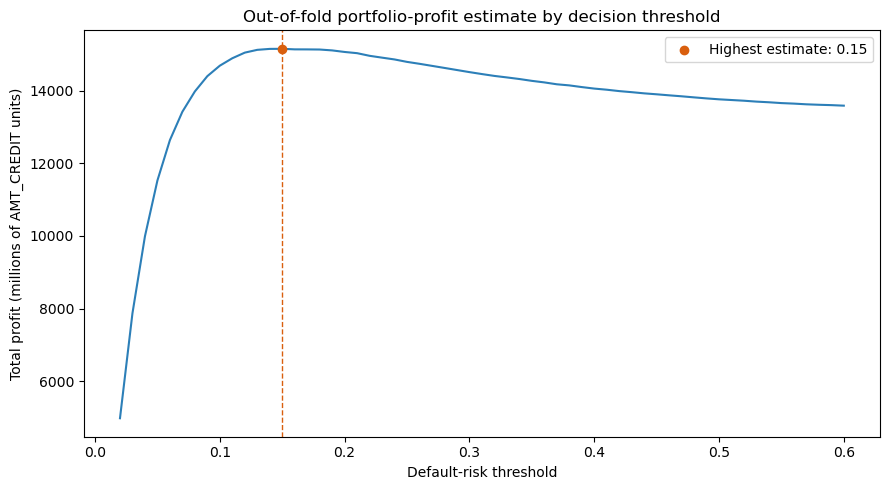

In [7]:
import matplotlib.pyplot as plt

credit_amounts = pd.read_csv(
    project_root / 'data' / 'processed' / 'train_prepared.csv',
    usecols=['SK_ID_CURR', 'AMT_CREDIT'],
)
threshold_data = oof_predictions.merge(
    credit_amounts, on='SK_ID_CURR', how='left', validate='one_to_one'
)
assert len(threshold_data) == len(oof_predictions)
assert threshold_data['AMT_CREDIT'].notna().all()

profit_margin = 0.14
loss_given_default = 0.75
thresholds = np.round(np.arange(0.02, 0.601, 0.01), 2)

def threshold_summary(frame, threshold, margin, lgd):
    approved = frame['predicted_default_probability'] < threshold
    denied = ~approved
    approved_count = int(approved.sum())
    default_rate_approved = (
        frame.loc[approved, 'TARGET'].mean() if approved_count else np.nan
    )
    profit = np.where(
        approved & (frame['TARGET'] == 0),
        margin * frame['AMT_CREDIT'],
        np.where(approved & (frame['TARGET'] == 1), -lgd * frame['AMT_CREDIT'], 0),
    ).sum()
    return {
        'Threshold': threshold,
        'Approval rate': approved.mean(),
        'Default rate among approved': default_rate_approved,
        'Precision': precision_score(frame['TARGET'], denied, zero_division=0),
        'Recall': recall_score(frame['TARGET'], denied, zero_division=0),
        'Total profit': profit,
    }

threshold_results = pd.DataFrame([
    threshold_summary(threshold_data, threshold, profit_margin, loss_given_default)
    for threshold in thresholds
])
optimal_result = threshold_results.loc[threshold_results['Total profit'].idxmax()]
optimal_threshold = float(optimal_result['Threshold'])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(threshold_results['Threshold'], threshold_results['Total profit'] / 1_000_000, color='#2C7FB8')
ax.scatter(
    optimal_threshold, optimal_result['Total profit'] / 1_000_000,
    color='#D95F0E', zorder=3, label=f'Highest estimate: {optimal_threshold:.2f}'
)
ax.axvline(optimal_threshold, color='#D95F0E', linestyle='--', linewidth=1)
ax.set(
    title='Out-of-fold portfolio-profit estimate by decision threshold',
    xlabel='Default-risk threshold',
    ylabel='Total profit (millions of AMT_CREDIT units)',
)
ax.legend()
plt.tight_layout()
plt.show()

### Threshold sensitivity

The table shows how the operating trade-off changes across the tested thresholds. Precision and recall describe the denied or flagged group; the default rate among approved applicants describes the residual risk in the approved portfolio.

In [8]:
display(
    threshold_results.style.format({
        'Threshold': '{:.2f}',
        'Approval rate': '{:.1%}',
        'Default rate among approved': '{:.1%}',
        'Precision': '{:.1%}',
        'Recall': '{:.1%}',
        'Total profit': '{:,.0f}',
    })
)

,Threshold,Approval rate,Default rate among approved,Precision,Recall,Total profit
0,0.02,19.4%,1.5%,9.7%,96.5%,"4,982,394,355"
1,0.03,32.4%,1.9%,11.0%,92.2%,"7,873,430,393"
2,0.04,43.1%,2.4%,12.4%,87.1%,"9,990,352,122"
3,0.05,51.6%,2.8%,13.6%,81.9%,"11,526,639,065"
4,0.06,58.4%,3.2%,14.9%,76.8%,"12,636,840,064"
5,0.07,64.0%,3.5%,16.1%,72.0%,"13,418,715,651"
6,0.08,68.5%,3.8%,17.3%,67.4%,"13,976,542,406"
7,0.09,72.4%,4.1%,18.4%,63.1%,"14,397,831,869"
8,0.10,75.5%,4.3%,19.6%,59.3%,"14,685,963,407"
9,0.11,78.2%,4.6%,20.6%,55.7%,"14,890,444,573"


### Economic-assumption sensitivity

Because the exact cost of default and profit on repayment are uncertain, this check repeats the threshold search for each combination of the stated LGD and profit-margin scenarios.

In [9]:
economic_scenarios = []
for lgd in (0.60, 0.75, 0.90):
    for margin in (0.10, 0.14, 0.18):
        scenario_results = pd.DataFrame([
            threshold_summary(threshold_data, threshold, margin, lgd)
            for threshold in thresholds
        ])
        best_scenario = scenario_results.loc[scenario_results['Total profit'].idxmax()]
        economic_scenarios.append({
            'LGD': lgd,
            'Profit margin': margin,
            'Profit-maximizing threshold': best_scenario['Threshold'],
            'Approval rate': best_scenario['Approval rate'],
            'Total profit': best_scenario['Total profit'],
        })

economic_sensitivity = pd.DataFrame(economic_scenarios)
display(
    economic_sensitivity.style.format({
        'LGD': '{:.0%}',
        'Profit margin': '{:.0%}',
        'Profit-maximizing threshold': '{:.2f}',
        'Approval rate': '{:.1%}',
        'Total profit': '{:,.0f}',
    })
)

,LGD,Profit margin,Profit-maximizing threshold,Approval rate,Total profit
0,60%,10%,0.13,82.6%,"10,316,899,292"
1,60%,14%,0.19,90.5%,"16,549,200,136"
2,60%,18%,0.24,94.0%,"23,036,409,813"
3,75%,10%,0.12,80.6%,"9,230,844,551"
4,75%,14%,0.15,85.9%,"15,150,551,015"
5,75%,18%,0.21,92.1%,"21,493,711,491"
6,90%,10%,0.10,75.5%,"8,262,089,624"
7,90%,14%,0.13,82.6%,"13,991,431,381"
8,90%,18%,0.18,89.5%,"20,054,185,538"


In [10]:
display(Markdown(f"""
### Recommended threshold under the base scenario: {optimal_threshold:.2f}

At this threshold, **precision is {optimal_result['Precision']:.1%}** and **recall is {optimal_result['Recall']:.1%}**. The modeled approval rate is **{optimal_result['Approval rate']:.1%}**, the observed default rate among approved applicants is **{optimal_result['Default rate among approved']:.1%}**, and the estimated total profit is **{optimal_result['Total profit']:,.0f}** in `AMT_CREDIT` units.

In plain language, lowering the threshold denies or reviews more applicants, which catches more eventual defaults but also turns away more loans that would have repaid. Raising it approves more applicants, which preserves lending volume but exposes the portfolio to more defaults. Under the stated 14% margin and 75% LGD assumptions, {optimal_threshold:.2f} produces the largest out-of-fold historical profit estimate among the tested thresholds. This is a decision-support recommendation, not an automatic-denial rule; business, legal, compliance, and fairness review are still required before deployment.
"""))


### Recommended threshold under the base scenario: 0.15

At this threshold, **precision is 24.5%** and **recall is 42.8%**. The modeled approval rate is **85.9%**, the observed default rate among approved applicants is **5.4%**, and the estimated total profit is **15,150,551,015** in `AMT_CREDIT` units.

In plain language, lowering the threshold denies or reviews more applicants, which catches more eventual defaults but also turns away more loans that would have repaid. Raising it approves more applicants, which preserves lending volume but exposes the portfolio to more defaults. Under the stated 14% margin and 75% LGD assumptions, 0.15 produces the largest out-of-fold historical profit estimate among the tested thresholds. This is a decision-support recommendation, not an automatic-denial rule; business, legal, compliance, and fairness review are still required before deployment.


## 5. Explainability

SHAP (SHapley Additive exPlanations) shows how each model input moved an individual prediction up or down relative to the model's average prediction. These charts use a random sample of 1,000 training applications selected with random state 42. They describe patterns learned by the model; they do not establish that a feature causes default.

In the beeswarm plot, each dot is an application. Dots to the right increased the model's predicted default risk and dots to the left reduced it. Color shows whether the feature value was relatively high or low.

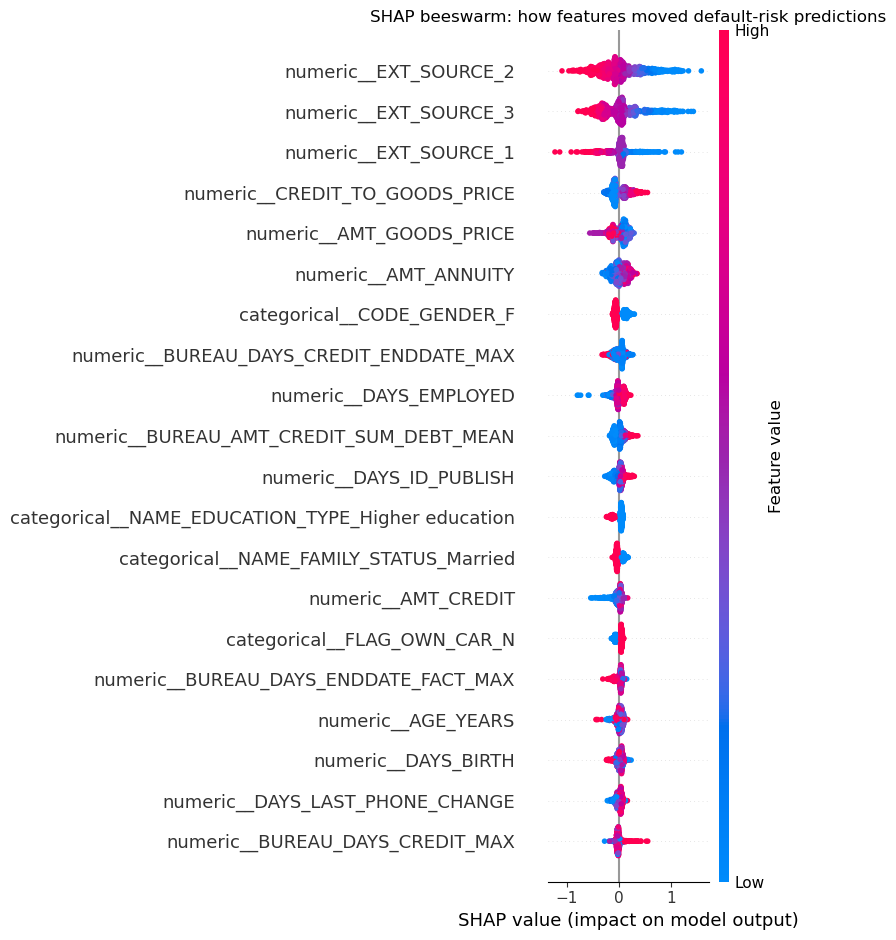

In [11]:
import matplotlib.pyplot as plt
import shap

explanation_sample = X_train.sample(n=1_000, random_state=42)
fitted_preprocessor = final_pipeline.named_steps['preprocessor']
transformed_sample = fitted_preprocessor.transform(explanation_sample)
if hasattr(transformed_sample, 'toarray'):
    transformed_sample = transformed_sample.toarray()

transformed_feature_names = fitted_preprocessor.get_feature_names_out()
transformed_sample_frame = pd.DataFrame(
    transformed_sample, columns=transformed_feature_names, index=explanation_sample.index
)
tree_explainer = shap.TreeExplainer(lightgbm_model)
shap_values = tree_explainer.shap_values(transformed_sample_frame)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
if np.asarray(shap_values).ndim == 3:
    shap_values = np.asarray(shap_values)[:, :, 1]
shap_values = np.asarray(shap_values)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_importance = (
    pd.DataFrame({
        'Feature': transformed_feature_names,
        'Mean absolute SHAP value': mean_abs_shap,
    })
    .sort_values('Mean absolute SHAP value', ascending=False, ignore_index=True)
)
top_shap_features = shap_importance.head(10).copy()

shap.summary_plot(
    shap_values, transformed_sample_frame, max_display=20, show=False
)
plt.title('SHAP beeswarm: how features moved default-risk predictions')
plt.tight_layout()
plt.show()

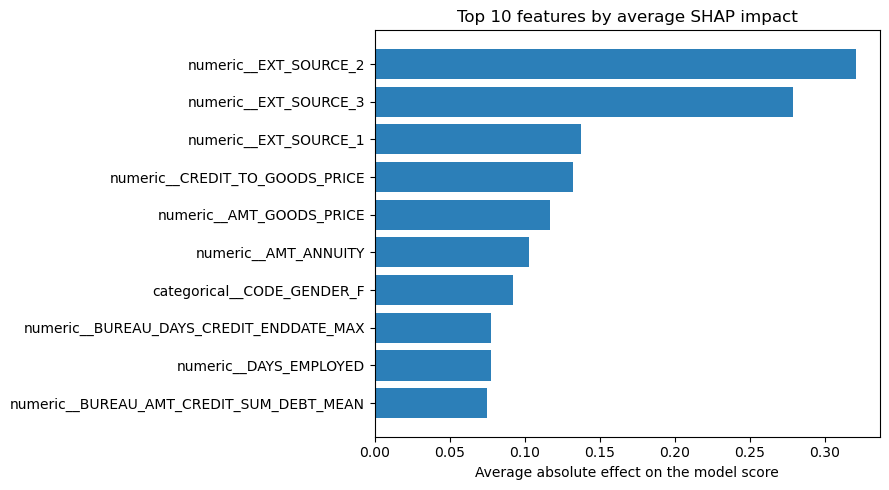

,Feature,Mean absolute SHAP value
0,numeric__EXT_SOURCE_2,0.3208
1,numeric__EXT_SOURCE_3,0.2785
2,numeric__EXT_SOURCE_1,0.1374
3,numeric__CREDIT_TO_GOODS_PRICE,0.1324
4,numeric__AMT_GOODS_PRICE,0.1165
5,numeric__AMT_ANNUITY,0.1027
6,categorical__CODE_GENDER_F,0.0921
7,numeric__BUREAU_DAYS_CREDIT_ENDDATE_MAX,0.0776
8,numeric__DAYS_EMPLOYED,0.0773
9,numeric__BUREAU_AMT_CREDIT_SUM_DEBT_MEAN,0.0747


In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    top_shap_features['Feature'][::-1],
    top_shap_features['Mean absolute SHAP value'][::-1],
    color='#2C7FB8',
)
ax.set(
    title='Top 10 features by average SHAP impact',
    xlabel='Average absolute effect on the model score',
    ylabel='',
)
plt.tight_layout()
plt.show()

display(top_shap_features.style.format({'Mean absolute SHAP value': '{:.4f}'}))

### Plain-English interpretation

The three external-source scores (`EXT_SOURCE_2`, `EXT_SOURCE_3`, and `EXT_SOURCE_1`) are the strongest features in this sample. Higher values of each were generally associated with **lower** predicted default risk.

A higher credit-to-goods-price ratio and a higher annuity amount were generally associated with **higher** predicted risk. The model also uses prior-credit context: a later maximum bureau credit-end date and a higher average prior-credit debt amount were generally associated with **higher** predicted risk in this sample. Employment history and the gender indicator also contributed, but less than the leading external-source and affordability features.

These are model associations, not explanations of why an applicant may default. They should be reviewed for policy, data-quality, fairness, and adverse-action implications before being used in a lending workflow.

## 6. Adverse Action Mapping

The table below translates the model's top SHAP features into draft consumer-facing reason language. It is a design aid, not an approved adverse-action notice. Under the U.S. Equal Credit Opportunity Act (ECOA) and Regulation B, a creditor taking adverse action must provide specific and accurate principal reasons for the action; this obligation applies when complex algorithms are used. See the [CFPB's Circular 2022-03](https://www.consumerfinance.gov/compliance/circulars/circular-2022-03-adverse-action-notification-requirements-in-connection-with-credit-decisions-based-on-complex-algorithms/). Legal and compliance teams must validate the mapping, reason selection, reason ordering, data provenance, and notice process before any deployment.

> **Protected-characteristic safeguard:** `CODE_GENDER_F` is a sex-related indicator. It is shown because it appears among the model's top technical features, but it must not be used as a consumer-facing denial reason. Its presence requires governance review and likely removal or mitigation before any production credit decision.

In [13]:
reason_mapping = pd.DataFrame([
    {
        'Technical feature': 'numeric__EXT_SOURCE_2',
        'Direction that increases risk': 'Lower value',
        'Human-readable denial reason': 'Limited or weak credit history with external agencies',
    },
    {
        'Technical feature': 'numeric__EXT_SOURCE_3',
        'Direction that increases risk': 'Lower value',
        'Human-readable denial reason': 'Limited or weak credit history with external agencies',
    },
    {
        'Technical feature': 'numeric__EXT_SOURCE_1',
        'Direction that increases risk': 'Lower value',
        'Human-readable denial reason': 'Limited or weak credit history with external agencies',
    },
    {
        'Technical feature': 'numeric__CREDIT_TO_GOODS_PRICE',
        'Direction that increases risk': 'Higher value',
        'Human-readable denial reason': 'Requested credit is high relative to the value of goods financed',
    },
    {
        'Technical feature': 'numeric__AMT_GOODS_PRICE',
        'Direction that increases risk': 'Lower value',
        'Human-readable denial reason': 'Lower stated value of goods being financed',
    },
    {
        'Technical feature': 'numeric__AMT_ANNUITY',
        'Direction that increases risk': 'Higher value',
        'Human-readable denial reason': 'Higher scheduled loan payment amount',
    },
    {
        'Technical feature': 'categorical__CODE_GENDER_F',
        'Direction that increases risk': 'Feature absent (not female)',
        'Human-readable denial reason': 'Do not use: protected sex-related characteristic; requires model governance remediation',
    },
    {
        'Technical feature': 'numeric__BUREAU_DAYS_CREDIT_ENDDATE_MAX',
        'Direction that increases risk': 'Higher value',
        'Human-readable denial reason': 'Longer remaining commitments in prior credit history',
    },
    {
        'Technical feature': 'numeric__DAYS_EMPLOYED',
        'Direction that increases risk': 'Higher value (closer to zero)',
        'Human-readable denial reason': 'Shorter reported employment tenure',
    },
    {
        'Technical feature': 'numeric__BUREAU_AMT_CREDIT_SUM_DEBT_MEAN',
        'Direction that increases risk': 'Higher value',
        'Human-readable denial reason': 'Higher average outstanding debt in prior credit history',
    },
])

adverse_action_table = (
    top_shap_features[['Feature']]
    .merge(reason_mapping, left_on='Feature', right_on='Technical feature', how='left')
    .drop(columns='Feature')
)
assert adverse_action_table['Human-readable denial reason'].notna().all()
display(adverse_action_table)

,Technical feature,Direction that increases risk,Human-readable denial reason
0,numeric__EXT_SOURCE_2,Lower value,Limited or weak credit history with external a...
1,numeric__EXT_SOURCE_3,Lower value,Limited or weak credit history with external a...
2,numeric__EXT_SOURCE_1,Lower value,Limited or weak credit history with external a...
3,numeric__CREDIT_TO_GOODS_PRICE,Higher value,Requested credit is high relative to the value...
4,numeric__AMT_GOODS_PRICE,Lower value,Lower stated value of goods being financed
5,numeric__AMT_ANNUITY,Higher value,Higher scheduled loan payment amount
6,categorical__CODE_GENDER_F,Feature absent (not female),Do not use: protected sex-related characterist...
7,numeric__BUREAU_DAYS_CREDIT_ENDDATE_MAX,Higher value,Longer remaining commitments in prior credit h...
8,numeric__DAYS_EMPLOYED,Higher value (closer to zero),Shorter reported employment tenure
9,numeric__BUREAU_AMT_CREDIT_SUM_DEBT_MEAN,Higher value,Higher average outstanding debt in prior credi...


### Illustrative denied-applicant reasons

The examples below are the three highest out-of-fold risk scores at or above the chosen threshold. Each reason is drawn from that applicant's largest positive SHAP contributions, after excluding the protected sex-related indicator. They demonstrate a traceable explanation workflow only; they are not customer notices and should never be issued without the required validation and compliance review.

In [14]:
training_ids = pd.read_csv(
    project_root / 'data' / 'processed' / 'train_prepared.csv', usecols=['SK_ID_CURR']
)
position_by_id = pd.Series(training_ids.index, index=training_ids['SK_ID_CURR'])
denied_examples = (
    threshold_data.loc[
        threshold_data['predicted_default_probability'] >= optimal_threshold
    ]
    .nlargest(3, 'predicted_default_probability')
    .copy()
)
example_positions = [position_by_id.loc[applicant_id] for applicant_id in denied_examples['SK_ID_CURR']]
example_predictors = X_train.iloc[example_positions]
example_transformed = fitted_preprocessor.transform(example_predictors)
if hasattr(example_transformed, 'toarray'):
    example_transformed = example_transformed.toarray()
example_shap_values = tree_explainer.shap_values(example_transformed)
if isinstance(example_shap_values, list):
    example_shap_values = example_shap_values[1]
if np.asarray(example_shap_values).ndim == 3:
    example_shap_values = np.asarray(example_shap_values)[:, :, 1]
example_shap_values = np.asarray(example_shap_values)

consumer_reason_lookup = (
    reason_mapping
    .loc[~reason_mapping['Human-readable denial reason'].str.startswith('Do not use')]
    .set_index('Technical feature')['Human-readable denial reason']
    .to_dict()
)

def top_individual_reasons(shap_row, number_of_reasons=3):
    reasons = []
    for feature_index in np.argsort(shap_row)[::-1]:
        feature = transformed_feature_names[feature_index]
        if shap_row[feature_index] <= 0:
            break
        reason = consumer_reason_lookup.get(feature)
        if reason and reason not in reasons:
            reasons.append(reason)
        if len(reasons) == number_of_reasons:
            break
    return reasons

example_rows = []
for example_number, (_, applicant) in enumerate(denied_examples.iterrows()):
    reasons = top_individual_reasons(example_shap_values[example_number])
    example_rows.append({
        'Applicant ID': int(applicant['SK_ID_CURR']),
        'Out-of-fold default-risk score': applicant['predicted_default_probability'],
        'Reason 1': reasons[0] if len(reasons) > 0 else 'No approved reason mapped',
        'Reason 2': reasons[1] if len(reasons) > 1 else 'No approved reason mapped',
        'Reason 3': reasons[2] if len(reasons) > 2 else 'No approved reason mapped',
    })

denied_applicant_examples = pd.DataFrame(example_rows)
display(
    denied_applicant_examples.style.format({
        'Out-of-fold default-risk score': '{:.1%}',
    })
)

,Applicant ID,Out-of-fold default-risk score,Reason 1,Reason 2,Reason 3
0,172897,93.0%,Limited or weak credit history with external agencies,Requested credit is high relative to the value of goods financed,Lower stated value of goods being financed
1,262411,92.3%,Limited or weak credit history with external agencies,Lower stated value of goods being financed,Requested credit is high relative to the value of goods financed
2,325932,91.2%,Limited or weak credit history with external agencies,Higher average outstanding debt in prior credit history,Lower stated value of goods being financed


## 7. Fairness Analysis

This screening compares outcomes at the selected decision threshold across recorded gender and education groups, using the out-of-fold scores. It reports group size, observed default rate, approval rate, and the approval-rate ratio relative to the most-approved group. A ratio below 0.80 is flagged using the four-fifths rule requested for this analysis.

> **Important:** The four-fifths rule is an employment-selection rule of thumb, not a lending safe harbor or a legal conclusion. The EEOC explains that it is a practical screening tool rather than a legal definition; see its [Uniform Guidelines Q&A](https://www.eeoc.gov/es/node/130157). For credit decisions, ECOA and Regulation B prohibit discrimination on protected bases, including sex; see the CFPB's [credit-discrimination guidance](https://www.consumerfinance.gov/consumer-tools/credit-reports-and-scores/credit-discrimination-is-illegal/). Legal and compliance review is required before deployment.

In [15]:
fairness_attributes = pd.read_csv(
    project_root / 'data' / 'processed' / 'train_prepared.csv',
    usecols=['SK_ID_CURR', 'CODE_GENDER', 'NAME_EDUCATION_TYPE'],
)
fairness_data = threshold_data.merge(
    fairness_attributes, on='SK_ID_CURR', how='left', validate='one_to_one'
)
assert len(fairness_data) == len(threshold_data)
fairness_data['Approved'] = (
    fairness_data['predicted_default_probability'] < optimal_threshold
)

def fairness_profile(frame, group_column):
    profile = (
        frame.assign(**{group_column: frame[group_column].fillna('Not reported')})
        .groupby(group_column, dropna=False)
        .agg(
            Count=('TARGET', 'size'),
            **{
                'Actual default rate': ('TARGET', 'mean'),
                'Approval rate': ('Approved', 'mean'),
            },
        )
        .reset_index()
        .sort_values('Approval rate', ascending=False, ignore_index=True)
    )
    profile['Approval-rate ratio'] = profile['Approval rate'] / profile['Approval rate'].max()
    profile['Four-fifths screen'] = np.where(
        profile['Approval-rate ratio'] < 0.80, 'Flag: below 0.80', 'No flag'
    )
    return profile

gender_fairness = fairness_profile(fairness_data, 'CODE_GENDER')
education_fairness = fairness_profile(fairness_data, 'NAME_EDUCATION_TYPE')

display(Markdown('### Gender comparison'))
display(gender_fairness.style.format({
    'Actual default rate': '{:.1%}',
    'Approval rate': '{:.1%}',
    'Approval-rate ratio': '{:.1%}',
}))
display(Markdown('### Education comparison'))
display(education_fairness.style.format({
    'Actual default rate': '{:.1%}',
    'Approval rate': '{:.1%}',
    'Approval-rate ratio': '{:.1%}',
}))

gender_high, gender_low = gender_fairness.iloc[0], gender_fairness.iloc[-1]
education_high, education_low = education_fairness.iloc[0], education_fairness.iloc[-1]
flag_count = (
    (gender_fairness['Approval-rate ratio'] < 0.80).sum()
    + (education_fairness['Approval-rate ratio'] < 0.80).sum()
)
display(Markdown(f"""
### Observed disparity summary

The four-fifths screen flags **{flag_count}** of the displayed groups. The gender approval gap is **{gender_high['Approval rate'] - gender_low['Approval rate']:.1%}**: `{gender_high['CODE_GENDER']}` has a {gender_high['Approval rate']:.1%} approval rate and `{gender_low['CODE_GENDER']}` has a {gender_low['Approval rate']:.1%} approval rate. Their observed default rates are {gender_high['Actual default rate']:.1%} and {gender_low['Actual default rate']:.1%}, respectively.

For education, `{education_high['NAME_EDUCATION_TYPE']}` has the highest approval rate ({education_high['Approval rate']:.1%}) and `{education_low['NAME_EDUCATION_TYPE']}` the lowest ({education_low['Approval rate']:.1%}); their observed default rates are {education_high['Actual default rate']:.1%} and {education_low['Actual default rate']:.1%}. These observed-rate differences provide context but do not by themselves justify the approval gaps or rule out proxy risk.
"""))

### Gender comparison

,CODE_GENDER,Count,Actual default rate,Approval rate,Approval-rate ratio,Four-fifths screen
0,F,202448,7.0%,89.2%,100.0%,No flag
1,M,105059,10.1%,79.6%,89.2%,No flag


### Education comparison

,NAME_EDUCATION_TYPE,Count,Actual default rate,Approval rate,Approval-rate ratio,Four-fifths screen
0,Higher education,74862,5.4%,93.5%,100.0%,No flag
1,Academic degree,164,1.8%,87.2%,93.2%,No flag
2,Incomplete higher,10276,8.5%,84.4%,90.2%,No flag
3,Secondary / secondary special,218389,8.9%,83.5%,89.3%,No flag
4,Lower secondary,3816,10.9%,79.0%,84.5%,No flag



### Observed disparity summary

The four-fifths screen flags **0** of the displayed groups. The gender approval gap is **9.6%**: `F` has a 89.2% approval rate and `M` has a 79.6% approval rate. Their observed default rates are 7.0% and 10.1%, respectively.

For education, `Higher education` has the highest approval rate (93.5%) and `Lower secondary` the lowest (79.0%); their observed default rates are 5.4% and 10.9%. These observed-rate differences provide context but do not by themselves justify the approval gaps or rule out proxy risk.


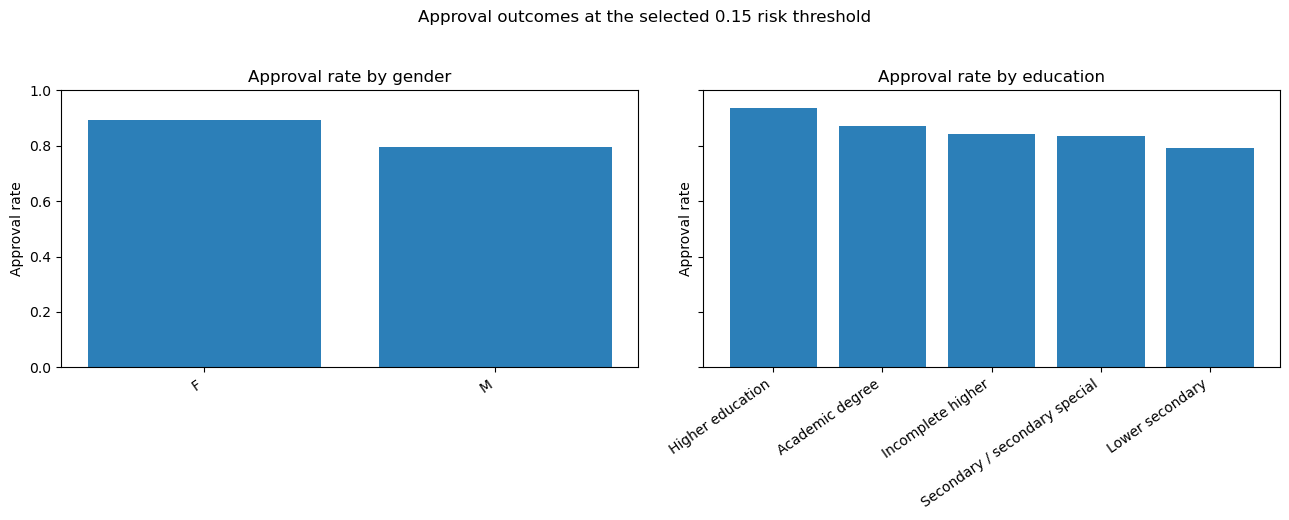

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for axis, profile, group_column, title in [
    (axes[0], gender_fairness, 'CODE_GENDER', 'Approval rate by gender'),
    (axes[1], education_fairness, 'NAME_EDUCATION_TYPE', 'Approval rate by education'),
]:
    colors = np.where(
        profile['Approval-rate ratio'] < 0.80, '#D95F0E', '#2C7FB8'
    )
    axis.bar(profile[group_column], profile['Approval rate'], color=colors)
    axis.set(title=title, ylabel='Approval rate', ylim=(0, 1))
    axis.tick_params(axis='x', rotation=35)
    for label in axis.get_xticklabels():
        label.set_ha('right')

fig.suptitle(
    f'Approval outcomes at the selected {optimal_threshold:.2f} risk threshold', y=1.03
)
plt.tight_layout()
plt.show()

### Interpretation and implications

A flagged approval-rate ratio identifies a material difference in who advances under this particular threshold; it does not prove unlawful discrimination, nor does the absence of a flag establish fairness. The observed default-rate column provides important context: a lower approval rate may coincide with a higher recorded default rate, but that comparison alone cannot establish that the gap is justified, necessary, or free of model error.

Gender is a protected characteristic under ECOA, so any gender disparity requires immediate legal and compliance review. Education is not a substitute protected-class analysis, but it can be a proxy for socioeconomic conditions or other protected characteristics and should be monitored as a potential proxy-risk signal. The model's direct use of `CODE_GENDER`—already visible in the SHAP analysis—is a deployment blocker until governance determines whether the feature must be removed, the model refit, and the resulting outcomes independently revalidated.

Before deploying any threshold, the credit-risk, legal, compliance, and fair-lending teams should review the data definitions, sampling and outcome quality, relevant protected-group analyses, proxy features, error rates, threshold alternatives, and adverse-action process. This notebook is a preliminary diagnostic, not a legal conclusion.

## 8. Limitations and Risks

- **Validation gap:** The three-fold cross-validated AUC (0.7645) exceeds the private Kaggle AUC (0.75871). This suggests the internal validation estimate was somewhat optimistic and future performance could be lower.
- **Limited setting and time period:** The data comes from a single lender and historical 2018 Kaggle competition data. It may not represent current applicants, other lenders, countries, products, economic conditions, or underwriting policies.
- **Opaque external scores:** `EXT_SOURCE_1`, `EXT_SOURCE_2`, and `EXT_SOURCE_3` are leading model inputs, but their underlying definitions, collection methods, coverage, and fairness properties are not transparent in this dataset.
- **Missing decision information:** The model does not include verified income, nor does it use prior application decisions and outcomes. Missing or unavailable information can change both risk estimates and the fairness of decisions.
- **Population and process drift:** Applicant mix, bureau coverage, data definitions, credit policy, collections, and macroeconomic conditions can change after deployment. Performance, calibration, missingness, feature distributions, approval outcomes, and fairness metrics need ongoing monitoring.
- **Fairness and proxy risk:** The current model directly uses a sex-related indicator and may learn proxies for protected characteristics through external scores, education, geography, occupation, or credit-history fields. The preliminary checks in this card do not resolve those risks.
- **Threshold economics are assumptions:** The selected 0.15 threshold is sensitive to the assumed 14% profit margin and 75% loss given default. Net interest margin excludes operating costs, and recoveries, fraud, prepayments, funding costs, capital costs, and customer impact are not fully modeled.

These limitations support a controlled, monitored review workflow—not unattended automated underwriting—until the identified data, governance, fairness, legal, and economic issues are addressed.